# Facebook Network – Community Detection & GNN Graph

Steps: 1) Load nodes & edges  2) Louvain  3) Spectral (5 communities)  4) Leiden  5) Comparison  6) Final graph for GNN

Run the cells **top to bottom**. Outputs are saved to `D:\GNN Mini project\facebook_outputs`.

## 0. Install packages (run once)

In [1]:
%pip install networkx numpy pandas matplotlib scikit-learn scipy python-igraph
# optional, for the GNN .pt file:
# %pip install torch torch_geometric

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Imports

In [2]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from sklearn.cluster import SpectralClustering
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score
from sklearn.model_selection import train_test_split

## Config

In [3]:
DATA_PATH = r"D:\GNN Mini project\facebook_combined.txt"
OUT_DIR = r"D:\GNN Mini project\facebook_outputs"
SEED = 42
N_SPECTRAL = 5          # Spectral_Clear_5_Communities
os.makedirs(OUT_DIR, exist_ok=True)

PALETTE = [
    "#e6194b", "#3cb44b", "#4363d8", "#f58231", "#911eb4", "#46f0f0",
    "#f032e6", "#bcf60c", "#008080", "#9a6324", "#800000", "#808000",
    "#000075", "#fabebe", "#e6beff", "#aaffc3", "#ffd8b1", "#a9a9a9",
]

## Helper functions

In [4]:
def relabel_by_size(comm_dict):
    """Relabel communities so 1 = largest, 2 = second largest, ..."""
    counts = pd.Series(comm_dict).value_counts()
    mapping = {old: new for new, old in enumerate(counts.index, start=1)}
    return {n: mapping[c] for n, c in comm_dict.items()}


def modularity_of(G, comm_dict):
    groups = {}
    for n, c in comm_dict.items():
        groups.setdefault(c, set()).add(n)
    return nx.community.modularity(G, list(groups.values()))


def report(name, G, comm_dict):
    sizes = pd.Series(comm_dict).value_counts().sort_index()
    print("=" * 75)
    print(name)
    print("=" * 75)
    print(f"Communities detected: {len(sizes)}")
    print(f"Modularity: {modularity_of(G, comm_dict):.4f}\n")
    print("Community sizes:")
    for c, s in sizes.items():
        print(f"Community {c}: {s:,} nodes")
    print()
    return sizes


def community_layout(G, comm_dict, seed=SEED):
    """Layout that places each community as a separate, clearly visible cluster."""
    groups = {}
    for n, c in comm_dict.items():
        groups.setdefault(c, []).append(n)

    k = len(groups)
    N = G.number_of_nodes()

    # super-graph of communities -> where each cluster centre goes
    S = nx.Graph()
    S.add_nodes_from(groups)
    for u, v in G.edges():
        cu, cv = comm_dict[u], comm_dict[v]
        if cu != cv:
            w = S[cu][cv]["weight"] + 1 if S.has_edge(cu, cv) else 1
            S.add_edge(cu, cv, weight=w)
    if k == 1:
        centers = {list(groups)[0]: np.array([0.0, 0.0])}
    else:
        centers = nx.spring_layout(S, k=2.5 / np.sqrt(k), seed=seed, scale=10 + k)

    pos = {}
    for c, nodes in groups.items():
        sub = G.subgraph(nodes)
        radius = 1.2 + 6.0 * np.sqrt(len(nodes) / N)
        if len(nodes) == 1:
            local = {nodes[0]: np.array([0.0, 0.0])}
        else:
            local = nx.spring_layout(sub, seed=seed, scale=radius,
                                     k=1.5 / np.sqrt(len(nodes)), iterations=80)
        for n, p in local.items():
            pos[n] = np.array(p) + np.array(centers[c])
    return pos, centers


def draw_communities(G, comm_dict, title, filename, show_ids=True):
    pos, centers = community_layout(G, comm_dict)
    sizes = pd.Series(comm_dict).value_counts().sort_index()
    color_of = {c: PALETTE[(c - 1) % len(PALETTE)] for c in sizes.index}

    fig, ax = plt.subplots(figsize=(16, 14))

    # edges (intra coloured, inter faint grey) - LineCollection is fast
    intra, intra_col, inter = [], [], []
    for u, v in G.edges():
        seg = (pos[u], pos[v])
        if comm_dict[u] == comm_dict[v]:
            intra.append(seg)
            intra_col.append(color_of[comm_dict[u]])
        else:
            inter.append(seg)
    ax.add_collection(LineCollection(inter, colors="#888888", linewidths=0.2, alpha=0.08, zorder=1))
    ax.add_collection(LineCollection(intra, colors=intra_col, linewidths=0.3, alpha=0.25, zorder=2))

    # nodes
    nodes = list(G.nodes())
    xy = np.array([pos[n] for n in nodes])
    deg = np.array([G.degree(n) for n in nodes])
    ax.scatter(xy[:, 0], xy[:, 1],
               s=6 + 40 * (deg / deg.max()),
               c=[color_of[comm_dict[n]] for n in nodes],
               edgecolors="white", linewidths=0.25, zorder=3)

    if show_ids:
        for c, ctr in centers.items():
            ax.text(ctr[0], ctr[1], str(c), fontsize=18, fontweight="bold",
                    ha="center", va="center", color="black", zorder=5,
                    bbox=dict(boxstyle="circle,pad=0.25", fc="white", ec="black", alpha=0.85))

    handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=color_of[c],
                      markersize=11, label=f"Community {c}: {s:,} nodes")
               for c, s in sizes.items()]
    ax.legend(handles=handles, loc="upper left", fontsize=10, frameon=True,
              title=f"{len(sizes)} communities", title_fontsize=11,
              ncol=1 if len(sizes) <= 12 else 2)

    ax.set_title(title, fontsize=18, fontweight="bold")
    ax.autoscale_view()
    ax.set_aspect("equal")
    ax.axis("off")
    plt.tight_layout()
    path = os.path.join(OUT_DIR, filename)
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"[saved] {path}")


def save_membership(comm_dict, name):
    df = pd.DataFrame({"node": list(comm_dict.keys()), "community": list(comm_dict.values())})
    df = df.sort_values("node")
    df.to_csv(os.path.join(OUT_DIR, f"{name}_membership.csv"), index=False)
    sizes = df["community"].value_counts().sort_index().rename_axis("community").reset_index(name="size")
    sizes.to_csv(os.path.join(OUT_DIR, f"{name}_sizes.csv"), index=False)

## 1. LOAD DATA  (nodes & edges)

FACEBOOK DATASET SUMMARY
Nodes            : 4,039
Edges            : 88,234
Average degree   : 43.69
Density          : 0.01082
Avg clustering   : 0.6055
Connected        : True
Components       : 1



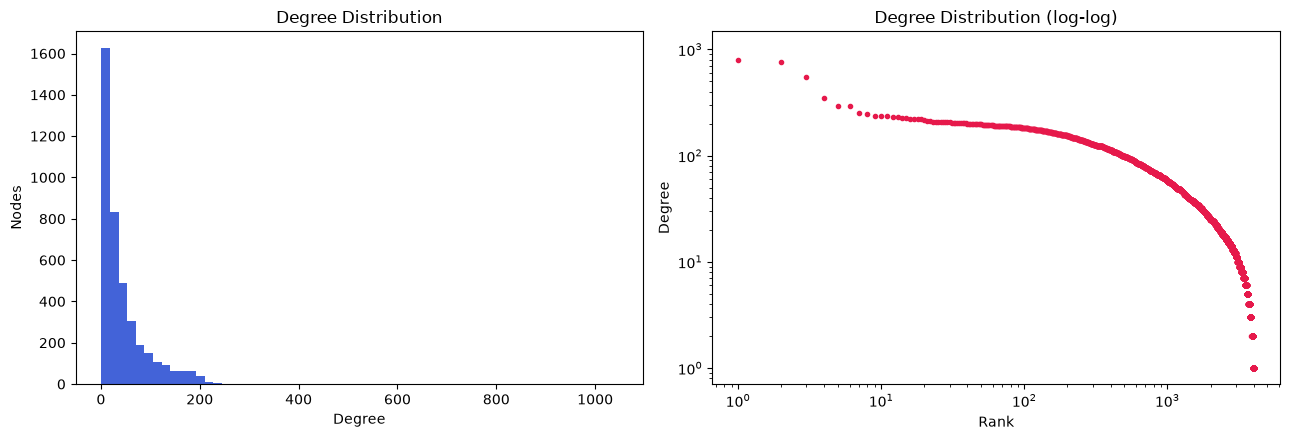

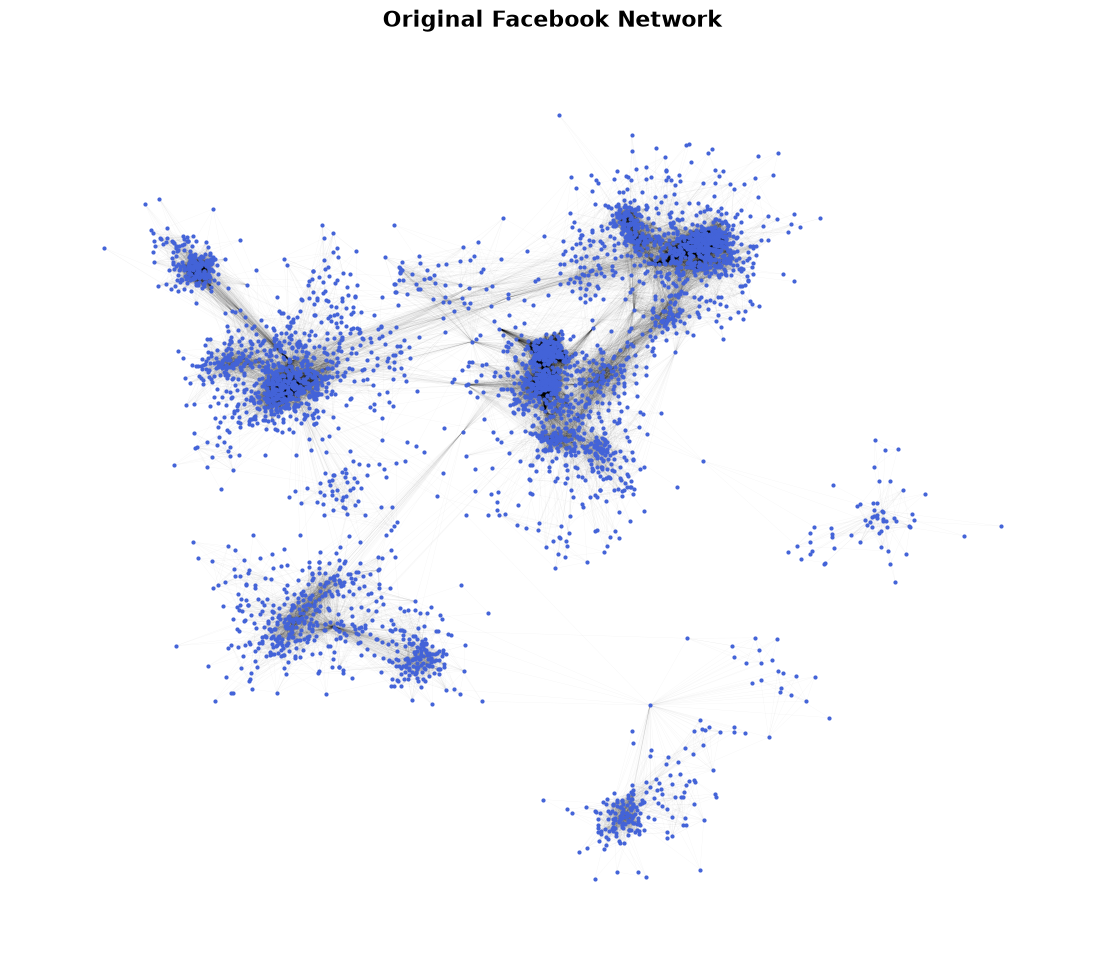

In [5]:
G = nx.read_edgelist(DATA_PATH, nodetype=int)
G.remove_edges_from(nx.selfloop_edges(G))
nodes_sorted = sorted(G.nodes())

print("=" * 75)
print("FACEBOOK DATASET SUMMARY")
print("=" * 75)
print(f"Nodes            : {G.number_of_nodes():,}")
print(f"Edges            : {G.number_of_edges():,}")
print(f"Average degree   : {np.mean([d for _, d in G.degree()]):.2f}")
print(f"Density          : {nx.density(G):.5f}")
print(f"Avg clustering   : {nx.average_clustering(G):.4f}")
print(f"Connected        : {nx.is_connected(G)}")
print(f"Components       : {nx.number_connected_components(G)}\n")

pd.DataFrame({"node": nodes_sorted}).to_csv(os.path.join(OUT_DIR, "nodes.csv"), index=False)
pd.DataFrame(list(G.edges()), columns=["source", "target"]).to_csv(
    os.path.join(OUT_DIR, "edges.csv"), index=False)

# Degree distribution plot
deg_seq = sorted([d for _, d in G.degree()], reverse=True)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(deg_seq, bins=60, color="#4363d8")
ax[0].set_title("Degree Distribution"); ax[0].set_xlabel("Degree"); ax[0].set_ylabel("Nodes")
ax[1].loglog(deg_seq, ".", color="#e6194b")
ax[1].set_title("Degree Distribution (log-log)"); ax[1].set_xlabel("Rank"); ax[1].set_ylabel("Degree")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Degree_Distribution.png"), dpi=200)
plt.show()

# Original graph (no communities)
pos_all = nx.spring_layout(G, seed=SEED, k=0.15, iterations=60)
fig, ax = plt.subplots(figsize=(14, 12))
nx.draw_networkx_edges(G, pos_all, alpha=0.05, width=0.2, ax=ax)
nx.draw_networkx_nodes(G, pos_all, node_size=4, node_color="#4363d8", ax=ax)
ax.set_title("Original Facebook Network", fontsize=16, fontweight="bold"); ax.axis("off")
plt.savefig(os.path.join(OUT_DIR, "Original_Facebook_Graph.png"), dpi=250, bbox_inches="tight")
plt.show()

## 2. LOUVAIN

LOUVAIN COMMUNITY DETECTION
Communities detected: 16
Modularity: 0.8349

Community sizes:
Community 1: 548 nodes
Community 2: 535 nodes
Community 3: 435 nodes
Community 4: 431 nodes
Community 5: 423 nodes
Community 6: 350 nodes
Community 7: 324 nodes
Community 8: 237 nodes
Community 9: 226 nodes
Community 10: 206 nodes
Community 11: 128 nodes
Community 12: 73 nodes
Community 13: 60 nodes
Community 14: 25 nodes
Community 15: 19 nodes
Community 16: 19 nodes



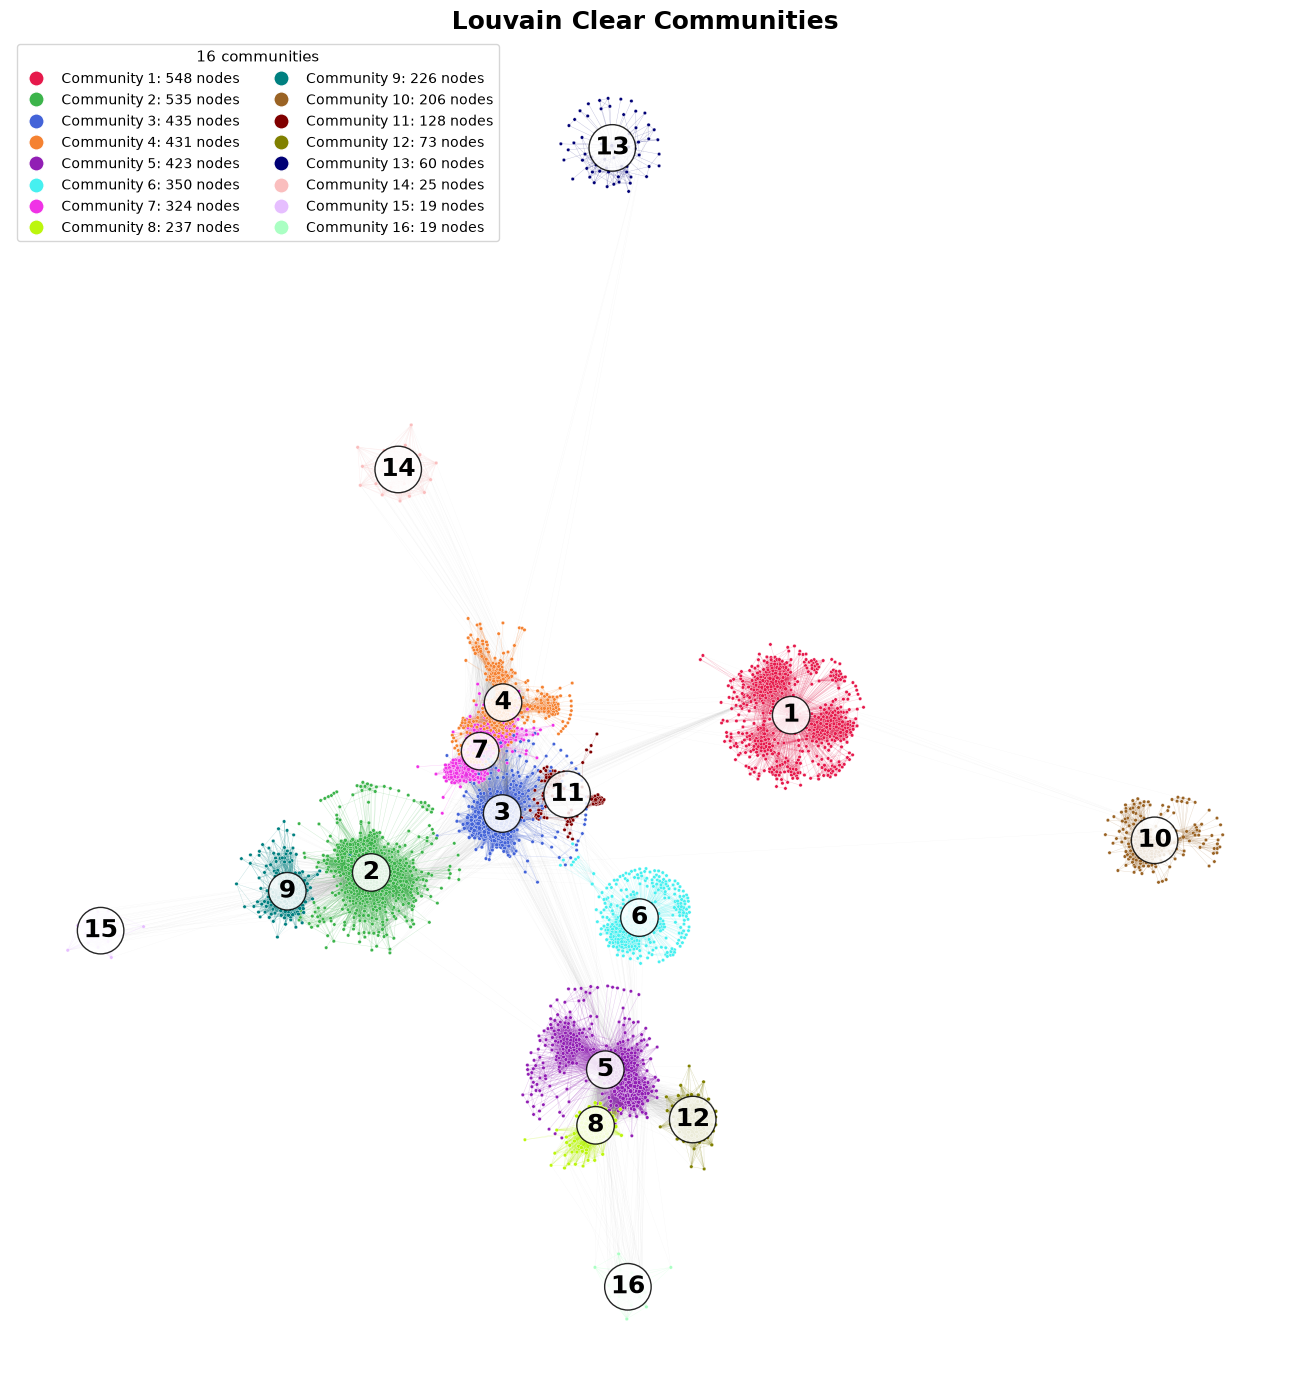

[saved] D:\GNN Mini project\facebook_outputs\Louvain_Clear_Communities.png


In [6]:
louvain_sets = nx.community.louvain_communities(G, seed=SEED, resolution=1.0)
louvain = relabel_by_size({n: i for i, s in enumerate(louvain_sets) for n in s})
report("LOUVAIN COMMUNITY DETECTION", G, louvain)
draw_communities(G, louvain, "Louvain Clear Communities", "Louvain_Clear_Communities.png")
save_membership(louvain, "Louvain")

## 3. SPECTRAL CLUSTERING (5 communities)

In [7]:
A = nx.to_scipy_sparse_array(G, nodelist=nodes_sorted, format="csr", dtype=float)
sc = SpectralClustering(n_clusters=N_SPECTRAL, affinity="precomputed",
                        assign_labels="kmeans", random_state=SEED, n_init=10)
labels = sc.fit_predict(A)
spectral = relabel_by_size({n: int(l) for n, l in zip(nodes_sorted, labels)})
report("SPECTRAL CLUSTERING (5 COMMUNITIES)", G, spectral)
draw_communities(G, spectral, "Spectral Clustering - Clear 5 Communities",
                 "Spectral_Clear_5_Communities.png")
save_membership(spectral, "Spectral")

ValueError: Only sparse matrices with 32-bit integer indices are accepted. Got int64 indices. Please do report a minimal reproducer on scikit-learn issue tracker so that support for your use-case can be studied by maintainers. See: https://scikit-learn.org/dev/developers/minimal_reproducer.html

## 4. LEIDEN  (python-igraph)

LEIDEN COMMUNITY DETECTION
Communities detected: 17
Modularity: 0.8357

Community sizes:
Community 1: 548 nodes
Community 2: 543 nodes
Community 3: 428 nodes
Community 4: 423 nodes
Community 5: 395 nodes
Community 6: 392 nodes
Community 7: 353 nodes
Community 8: 237 nodes
Community 9: 226 nodes
Community 10: 206 nodes
Community 11: 73 nodes
Community 12: 60 nodes
Community 13: 54 nodes
Community 14: 38 nodes
Community 15: 25 nodes
Community 16: 19 nodes
Community 17: 19 nodes



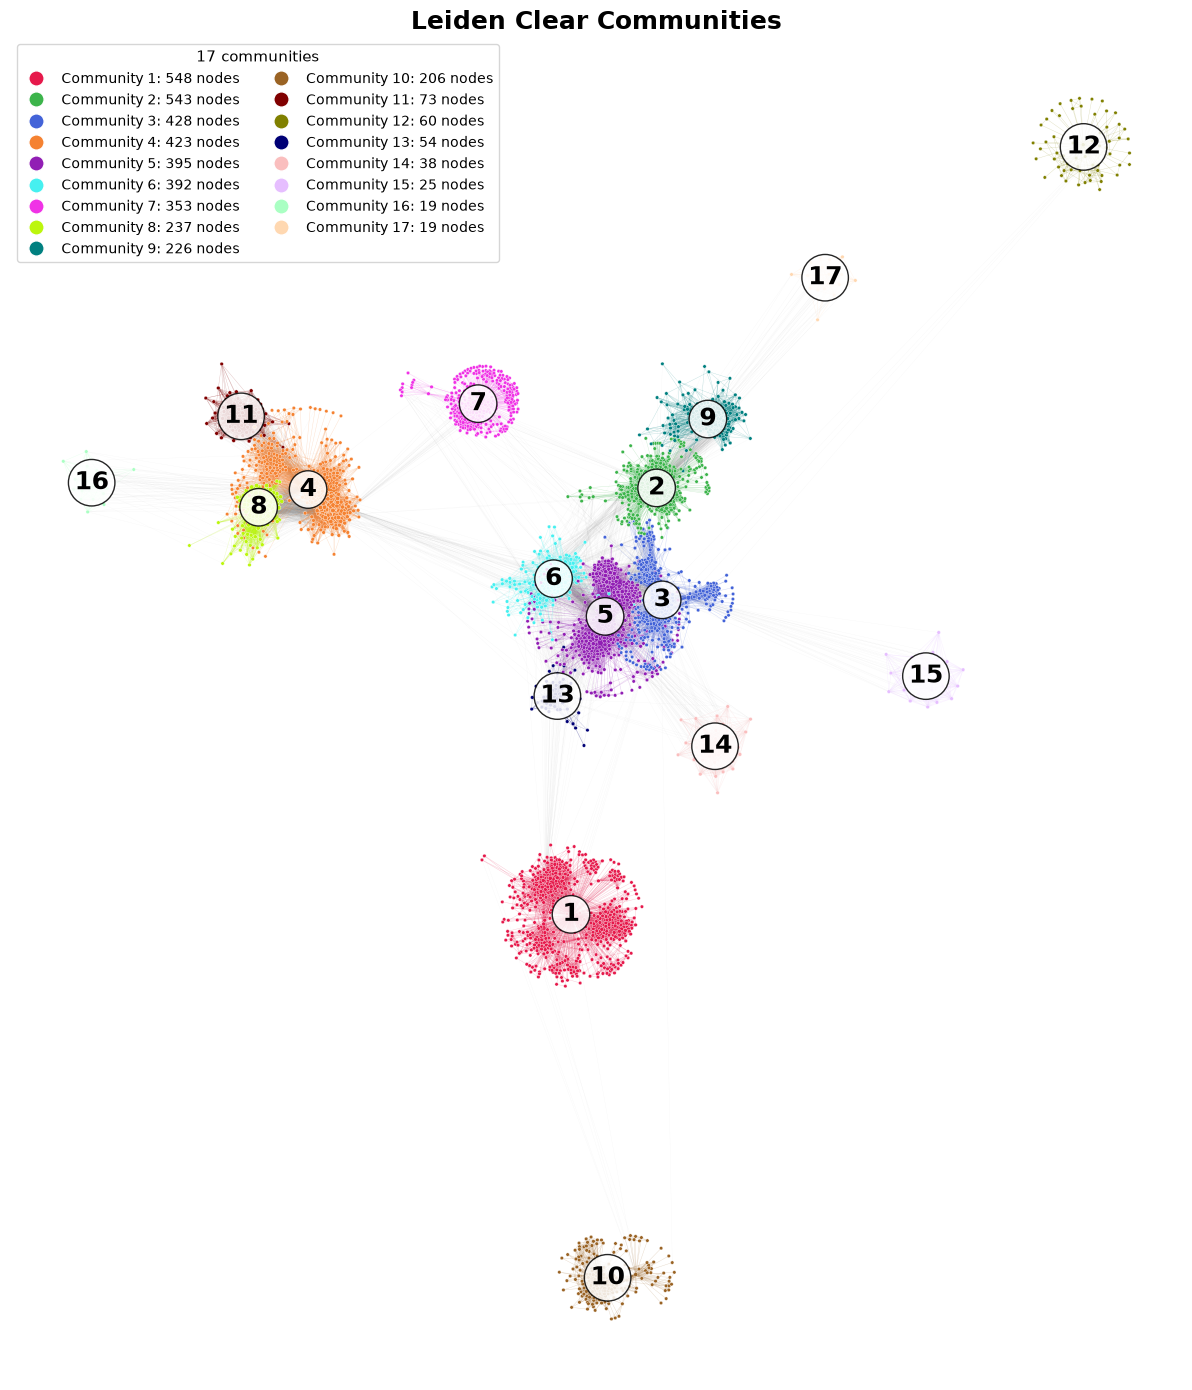

[saved] D:\GNN Mini project\facebook_outputs\Leiden_Clear_Communities.png


In [8]:
import igraph as ig
idx = {n: i for i, n in enumerate(nodes_sorted)}
ig_g = ig.Graph(n=len(nodes_sorted), edges=[(idx[u], idx[v]) for u, v in G.edges()])
import random; random.seed(SEED)
leiden_part = ig_g.community_leiden(objective_function="modularity", n_iterations=-1)
leiden = relabel_by_size({n: leiden_part.membership[idx[n]] for n in nodes_sorted})
report("LEIDEN COMMUNITY DETECTION", G, leiden)
draw_communities(G, leiden, "Leiden Clear Communities", "Leiden_Clear_Communities.png")
save_membership(leiden, "Leiden")

## 5. COMPARISON OF METHODS

In [9]:
methods = {"Louvain": louvain, "Spectral": spectral, "Leiden": leiden}
rows = []
for name, c in methods.items():
    rows.append({"Method": name, "Communities": len(set(c.values())),
                 "Modularity": round(modularity_of(G, c), 4),
                 "Largest": max(pd.Series(c).value_counts()),
                 "Smallest": min(pd.Series(c).value_counts())})
comp = pd.DataFrame(rows)
print("=" * 75); print("METHOD COMPARISON"); print("=" * 75)
print(comp.to_string(index=False)); print()
comp.to_csv(os.path.join(OUT_DIR, "Method_Comparison.csv"), index=False)

names = list(methods)
nmi = pd.DataFrame(index=names, columns=names, dtype=float)
ari = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        la = [methods[a][n] for n in nodes_sorted]
        lb = [methods[b][n] for n in nodes_sorted]
        nmi.loc[a, b] = normalized_mutual_info_score(la, lb)
        ari.loc[a, b] = adjusted_rand_score(la, lb)
print("NMI between methods:\n", nmi.round(3), "\n")
print("ARI between methods:\n", ari.round(3), "\n")
nmi.to_csv(os.path.join(OUT_DIR, "NMI_matrix.csv")); ari.to_csv(os.path.join(OUT_DIR, "ARI_matrix.csv"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
comp.plot.bar(x="Method", y="Modularity", ax=ax[0], legend=False, color="#4363d8", rot=0)
ax[0].set_title("Modularity by Method"); ax[0].set_ylim(0, 1)
comp.plot.bar(x="Method", y="Communities", ax=ax[1], legend=False, color="#3cb44b", rot=0)
ax[1].set_title("Number of Communities")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "Method_Comparison.png"), dpi=200); plt.show()

NameError: name 'spectral' is not defined

## 6. FINAL GRAPH USED FOR GNN

In [16]:
pip install networkx numpy pandas matplotlib scikit-learn torch torch-geometric

   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.5/126.7 MB 675.6 kB/s eta 0:03:07
   ---------------------------------------- 0.5/126.7 MB 675.6 kB/s eta 0:03:07
   ---------------------------------------- 0.8/126.7 MB 734.6 kB/s eta 0:02:52
   ---------------------------------------- 1.0/126.7 MB 790.7 kB/s eta 0:02:39
   ---------------------------------------- 1.3/126.7 MB 819.3 kB/s eta 0:02:34
   ---------------------------------------- 1.3/126.7 MB 819.3 kB/s eta 0:02:34
   ---------------------------------------- 1.6/126.7 MB 827.4 kB/s eta 0:02:32
    --------------------------------------- 1.8/126.7 MB 836.8 kB/s eta 0:02:30
    -


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
DATASET_PATH = r"D:\GNN Mini project\facebook_combined.txt"

OUTPUT_DIR = r"D:\GNN Mini project\GRAPHSAGE_RESULTS"

In [20]:

# ============================================================
# FACEBOOK COMMUNITY DETECTION USING GRAPHSAGE
# GraphSAGE + Unsupervised Learning + KMeans + Visualization
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from torch_geometric.nn import SAGEConv
from torch_geometric.utils import to_undirected, negative_sampling
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
EPOCHS = 100
HIDDEN_CHANNELS = 32
EMBEDDING_DIM = 16
NUM_COMMUNITIES = 5

DATASET_PATH = r"D:\GNN Mini project\facebook_combined.txt"
OUTPUT_DIR = r"D:\GNN Mini project\GRAPHSAGE_RESULTS"

os.makedirs(OUTPUT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ============================================================
# 2. LOAD FACEBOOK DATASET
# ============================================================

print("\nLoading Facebook dataset...")

G = nx.read_edgelist(DATASET_PATH, nodetype=int)
G.remove_edges_from(nx.selfloop_edges(G))

if not nx.is_connected(G):
    largest_component = max(nx.connected_components(G), key=len)
    G = G.subgraph(largest_component).copy()

print("\n========== DATASET INFORMATION ==========")
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Connected:", nx.is_connected(G))
print("Average degree:", round(np.mean([d for _, d in G.degree()]), 2))
print("Density:", round(nx.density(G), 6))

# ============================================================
# 3. NODE INDEXING
# ============================================================

nodes_sorted = sorted(G.nodes())
node_to_index = {node: i for i, node in enumerate(nodes_sorted)}
num_nodes = len(nodes_sorted)

# ============================================================
# 4. NODE FEATURE GENERATION
# ============================================================

print("\nGenerating node features...")

degree_dict = dict(G.degree())
clustering_dict = nx.clustering(G)
pagerank_dict = nx.pagerank(G)
core_dict = nx.core_number(G)

features = []

for node in nodes_sorted:
    features.append([
        degree_dict[node],
        clustering_dict[node],
        pagerank_dict[node],
        core_dict[node]
    ])

X = np.asarray(features, dtype=np.float32)
X = StandardScaler().fit_transform(X)

x = torch.tensor(X, dtype=torch.float32, device=device)

print("Feature matrix:", x.shape)

# ============================================================
# 5. EDGE INDEX GENERATION
# ============================================================

edges = [
    (node_to_index[u], node_to_index[v])
    for u, v in G.edges()
]

edge_index = torch.tensor(
    edges, dtype=torch.long
).t().contiguous()

edge_index = to_undirected(edge_index).to(device)

print("Edge index:", edge_index.shape)

# ============================================================
# 6. GRAPHSAGE MODEL
# ============================================================

class GraphSAGE(torch.nn.Module):

    def __init__(self, input_channels, hidden_channels, embedding_channels):
        super().__init__()

        self.conv1 = SAGEConv(input_channels, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, embedding_channels)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.2, training=self.training)
        x = self.conv2(x, edge_index)
        return x


model = GraphSAGE(
    x.shape[1],
    HIDDEN_CHANNELS,
    EMBEDDING_DIM
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

# ============================================================
# 7. GRAPHSAGE TRAINING
# ============================================================

print("\n========== GRAPHSAGE TRAINING ==========")

for epoch in range(1, EPOCHS + 1):

    model.train()
    optimizer.zero_grad()

    embeddings = model(x, edge_index)

    src, dst = edge_index

    positive_score = (embeddings[src] * embeddings[dst]).sum(dim=1)

    negative_edge_index = negative_sampling(
        edge_index=edge_index,
        num_nodes=num_nodes,
        num_neg_samples=edge_index.shape[1]
    )

    neg_src, neg_dst = negative_edge_index

    negative_score = (
        embeddings[neg_src] * embeddings[neg_dst]
    ).sum(dim=1)

    loss = (
        F.softplus(-positive_score).mean()
        + F.softplus(negative_score).mean()
    )

    loss.backward()
    optimizer.step()

    if epoch % 10 == 0:
        print(f"Epoch {epoch}/{EPOCHS} | Loss: {loss.item():.4f}")

# ============================================================
# 8. GENERATE EMBEDDINGS
# ============================================================

model.eval()

with torch.no_grad():
    embeddings = model(x, edge_index).cpu().numpy()

np.save(
    os.path.join(OUTPUT_DIR, "GraphSAGE_Embeddings.npy"),
    embeddings
)

torch.save(
    model.state_dict(),
    os.path.join(OUTPUT_DIR, "GraphSAGE_Model.pth")
)

print("\nEmbedding shape:", embeddings.shape)

# ============================================================
# 9. KMEANS COMMUNITY DETECTION
# ============================================================

print("\n========== KMEANS COMMUNITY DETECTION ==========")

kmeans = KMeans(
    n_clusters=NUM_COMMUNITIES,
    random_state=SEED,
    n_init=10
)

community_labels = kmeans.fit_predict(embeddings)

results = pd.DataFrame({
    "Node_ID": nodes_sorted,
    "GraphSAGE_Community": community_labels
})

results.to_csv(
    os.path.join(OUTPUT_DIR, "GraphSAGE_Community_Labels.csv"),
    index=False
)

community_counts = results[
    "GraphSAGE_Community"
].value_counts().sort_index()

print("\nCommunity sizes:")

for community, count in community_counts.items():
    print(f"Community {community}: {count} nodes")

# ============================================================
# 10. GRAPH COMMUNITY VISUALIZATION
# ============================================================

print("\nGenerating GraphSAGE community graph...")

colors = [community_labels[node_to_index[n]] for n in G.nodes()]
node_sizes = [8 + G.degree(n) * 1.5 for n in G.nodes()]

pos = nx.spring_layout(
    G,
    seed=SEED,
    k=0.15,
    iterations=30
)

plt.figure(figsize=(16, 12))

nx.draw_networkx_edges(
    G, pos,
    alpha=0.08,
    width=0.3,
    edge_color="gray"
)

nodes_plot = nx.draw_networkx_nodes(
    G, pos,
    node_color=colors,
    cmap=plt.cm.tab10,
    node_size=node_sizes,
    alpha=0.9
)

plt.title(
    "Facebook Social Network - GraphSAGE Community Detection",
    fontsize=18,
    fontweight="bold"
)

plt.colorbar(nodes_plot, label="GraphSAGE Community")
plt.axis("off")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "Final_GraphSAGE_Community_Graph.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 11. TSNE EMBEDDING VISUALIZATION
# ============================================================

print("\nGenerating embedding visualization...")

tsne = TSNE(
    n_components=2,
    random_state=SEED,
    perplexity=min(30, num_nodes - 1),
    init="pca",
    learning_rate="auto"
)

embedding_2d = tsne.fit_transform(embeddings)

plt.figure(figsize=(12, 9))

scatter = plt.scatter(
    embedding_2d[:, 0],
    embedding_2d[:, 1],
    c=community_labels,
    cmap=plt.cm.tab10,
    s=12,
    alpha=0.8
)

plt.title("GraphSAGE Node Embedding Clusters", fontsize=16)
plt.xlabel("Embedding Dimension 1")
plt.ylabel("Embedding Dimension 2")
plt.colorbar(scatter, label="GraphSAGE Community")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "GraphSAGE_Embedding_Clusters.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 12. COMMUNITY SIZE VISUALIZATION
# ============================================================

plt.figure(figsize=(9, 6))

community_counts.plot(kind="bar", edgecolor="black")

plt.title("GraphSAGE Community Size Distribution", fontsize=15)
plt.xlabel("Community")
plt.ylabel("Number of Nodes")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "GraphSAGE_Community_Sizes.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 13. FINAL RESULTS
# ============================================================

print("\n==========================================")
print("GRAPHSAGE EXECUTION COMPLETED")
print("==========================================")

print("Dataset: Facebook")
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Embedding dimensions:", embeddings.shape[1])
print("Communities:", NUM_COMMUNITIES)

print("\nSaved output files:")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(filename)

print("\nOutput folder:")
print(OUTPUT_DIR)


ImportError: `torch` can only be initialized once per process, so this module cannot be imported again: neither via `importlib.reload(torch)`, nor by re-importing after a failed `import torch`.